In [1]:
import numpy as np
import pandas as pd
import pymannkendall as mk
from scipy import stats

# name, units, NASA source
VARIABLES = {
    "T2M":           ("Air temperature",      "°C",     "MERRA-2"),
    "PRECTOTCORR":   ("Rainfall (model)",     "mm/day", "MERRA-2"),
    "gpm_rain":      ("Rainfall (satellite)", "mm/day", "GPM IMERG"),
    "RH2M":          ("Humidity",             "%",      "MERRA-2"),
    "GWETTOP":       ("Topsoil wetness",      "0-1",    "MERRA-2"),
    "soil_moisture": ("Soil moisture",        "kg/m²",  "GLDAS"),
    "evaporation":   ("Evaporation",          "mm/day", "GLDAS"),
    "runoff":        ("Runoff",               "mm/day", "GLDAS"),
    "aerosol":       ("Haze (aerosol)",       "AOD",    "MERRA-2 aerosols"),
    "dust":          ("Dust",                 "AOD",    "MERRA-2 aerosols"),
}

df = pd.read_csv("all_data.csv", parse_dates=["date"])
df["year"] = df["date"].dt.year

def trend_test(years, values):
    """Linear trend, 95% CI, t-test and Mann-Kendall on yearly values."""
    t = years - years.mean()
    fit = stats.linregress(t, values)
    half = stats.t.ppf(0.975, len(values) - 2) * fit.stderr
    mk_p = mk.original_test(values).p
    return fit.slope * 10, half * 10, fit.pvalue, mk_p        # per decade

rows = []
for place, g in df.groupby("place"):
    for col, (name, units, source) in VARIABLES.items():
        s = g[["year", col]].dropna()
        yearly = s.groupby("year")[col].mean()                  # yearly average removes the seasonal cycle
        yearly = yearly[s.groupby("year").size() == 12]          # only complete years
        if len(yearly) < 10:
            continue
        rate, ci, p_t, p_mk = trend_test(yearly.index.values.astype(float), yearly.values)
        both = p_t < 0.05 and p_mk < 0.05
        rows.append({
            "Place": place.title(), "Variable": name, "Source": source, "Units": units,
            "Years": f"{yearly.index.min()}–{yearly.index.max()}",
            "Change per decade": round(rate, 4),
            "95% CI ±": round(ci, 4),
            "p (t-test)": round(p_t, 4),
            "p (Mann-Kendall)": round(p_mk, 4),
            "Direction": "Rising" if rate > 0 else "Falling",
            "Significant?": "Yes" if both else "Borderline" if min(p_t, p_mk) < 0.05 else "No",
        })

results = pd.DataFrame(rows)

# Correct for testing many things at once (Benjamini–Hochberg false discovery rate)
p = results["p (t-test)"].values
order = np.argsort(p)
q = p[order] * len(p) / np.arange(1, len(p) + 1)
q = np.minimum.accumulate(q[::-1])[::-1]
results.loc[results.index[order], "q (FDR)"] = np.minimum(q, 1).round(4)

results.style.map(
    lambda v: "background-color: #d4edda" if v == "Yes"
    else "background-color: #fff3cd" if v == "Borderline"
    else "background-color: #f8d7da" if v == "No" else "",
    subset=["Significant?"],
)

,Place,Variable,Source,Units,Years,Change per decade,95% CI ±,p (t-test),p (Mann-Kendall),Direction,Significant?,q (FDR)
0,Amazon,Air temperature,MERRA-2,°C,1981–2024,0.325800,0.134500,0.000000,0.000100,Rising,Yes,0.000000
1,Amazon,Rainfall (model),MERRA-2,mm/day,1981–2024,-0.394900,0.226300,0.001000,0.001900,Falling,Yes,0.008000
2,Amazon,Rainfall (satellite),GPM IMERG,mm/day,2000–2024,-0.461900,0.528600,0.083800,0.129000,Falling,No,0.111700
3,Amazon,Humidity,MERRA-2,%,1981–2024,-0.831300,0.613000,0.009100,0.036300,Falling,Yes,0.022800
4,Amazon,Topsoil wetness,MERRA-2,0-1,1981–2024,-0.015400,0.013600,0.027800,0.042000,Falling,Yes,0.046300
5,Amazon,Soil moisture,GLDAS,kg/m²,2000–2024,-0.650300,0.615900,0.039400,0.107100,Falling,Borderline,0.060600
6,Amazon,Evaporation,GLDAS,mm/day,2000–2024,0.077300,0.131500,0.236200,0.338300,Rising,No,0.304800
7,Amazon,Runoff,GLDAS,mm/day,2000–2024,0.028200,0.122700,0.639200,0.726100,Rising,No,0.691000
8,Amazon,Haze (aerosol),MERRA-2 aerosols,AOD,2000–2024,0.026100,0.020500,0.015000,0.058500,Rising,Borderline,0.028600
9,Amazon,Dust,MERRA-2 aerosols,AOD,2000–2024,0.002700,0.001500,0.001300,0.016100,Rising,Yes,0.008000


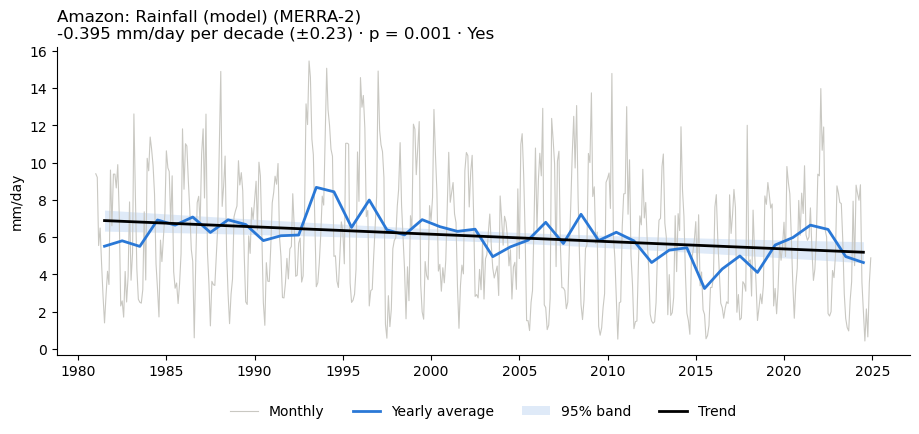

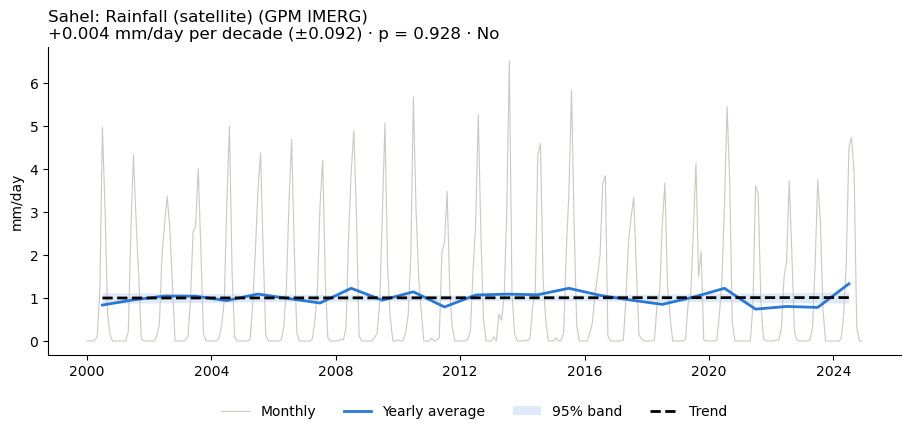

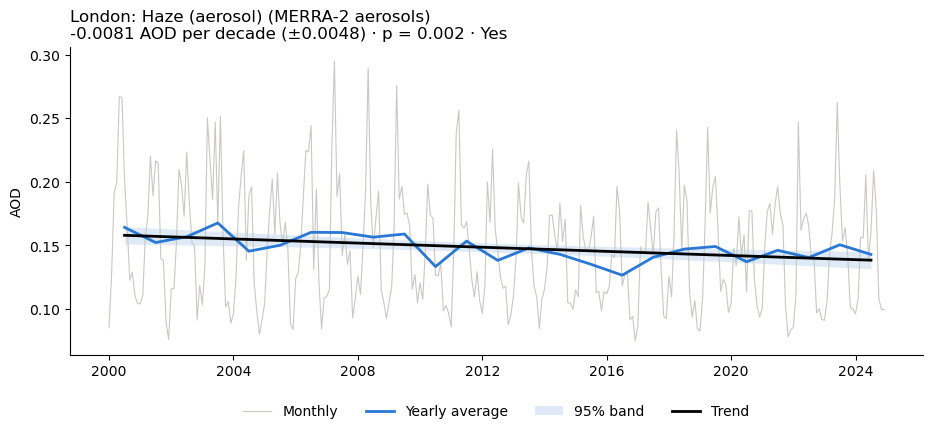

In [2]:
import matplotlib.pyplot as plt

def plot_trend(place, col):
    """Monthly data, yearly averages, trend line and 95% band, with the verdict in the title."""
    name, units, source = VARIABLES[col]
    g = df[df["place"] == place.lower()][["date", "year", col]].dropna()
    yearly = g.groupby("year")[col].mean()
    yearly = yearly[g.groupby("year").size() == 12]
    t = yearly.index.values.astype(float)
    fit = stats.linregress(t - t.mean(), yearly.values)
    line = fit.intercept + fit.slope * (t - t.mean())
    resid_sd = np.sqrt(np.sum((yearly.values - line) ** 2) / (len(t) - 2))
    band = stats.t.ppf(0.975, len(t) - 2) * resid_sd * np.sqrt(1 / len(t) + (t - t.mean()) ** 2 / np.sum((t - t.mean()) ** 2))
    r = results[(results.Place == place.title()) & (results.Variable == name)].iloc[0]

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(g["date"], g[col], color="#c9c8c2", lw=0.8, label="Monthly")
    mid = pd.to_datetime([f"{int(y)}-07-01" for y in t])
    ax.plot(mid, yearly.values, color="#2a78d6", lw=2, label="Yearly average")
    ax.fill_between(mid, line - band, line + band, color="#2a78d6", alpha=0.15, lw=0, label="95% band")
    ax.plot(mid, line, color="black", lw=2, ls="-" if r["Significant?"] == "Yes" else "--", label="Trend")
    ax.set_title(f"{place.title()}: {name} ({source})\n"
                 f"{r['Change per decade']:+.3g} {units} per decade (±{r['95% CI ±']:.2g}) · "
                 f"p = {r['p (t-test)']:.3f} · {r['Significant?']}", loc="left")
    ax.set_ylabel(units)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

# Examples: change these to any place / column
plot_trend("amazon", "PRECTOTCORR")
plot_trend("sahel", "gpm_rain")
plot_trend("london", "aerosol")